# Cell-level contrastive embeddings: extraction, UMAP, and sub-class discovery

This notebook has two independent parts:

1. **Part 1 - Extract.** Run the trained panoptic model over a folder of
   images, saving for every image a full-resolution **cell mask** and, for
   every detected cell, its pooled **contrastive feature embedding** plus
   phenotype label and bookkeeping info (bbox, centroid, source image).
   Needs a GPU, detectron2, and the trained checkpoint.

2. **Part 2 - Analyze.** Load the saved `cells.npz` + mask files, project
   the embeddings with **UMAP** (or t-SNE), look for **sub-classes** within
   the existing phenotype calls with KMeans, and make figures that pair the
   **original image** with the **embedding distribution**.

Part 2 only needs `contrast_learning.py`, numpy/pandas/sklearn/umap-learn/
matplotlib, the saved `cells.npz` + `masks/` folder, and the original
images. **No model, GPU, or detectron2 required** - this is what you
re-run on a different machine after copying over the `output_folder`.

If you only want to re-analyze previously extracted results, skip to
**Part 2** below and point `OUTPUT_FOLDER` / `IMAGE_FOLDER` at your data.

## Part 1 - Extract per-image masks and per-cell embeddings

Requires GPU + detectron2 + the trained checkpoint.

In [ ]:
import os
import sys

sys.path.insert(0, os.path.abspath("./detectron2"))
sys.path.insert(0, os.path.abspath("."))
sys.path.insert(0, os.path.abspath("./projects/Panoptic-DeepLab/"))

# Only needed if your dataset is registered through DETECTRON2_DATASETS;
# harmless to leave set even when you are only running inference.
os.environ.setdefault("DETECTRON2_DATASETS", "/path/to/datasets/")

In [2]:
from detectron2.config import get_cfg
from detectron2.engine import default_setup
from detectron2.projects.panoptic_deeplab import (
    PanopticDeeplabDatasetMapper,
    add_panoptic_deeplab_config,
)

from prediction import Predictor

/home/liwa/miniconda3/envs/oneformer/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Configuration -- edit these for your machine

Everything below is the only thing that should need to change when you
move this notebook to a different machine.

In [7]:
# --- Part 1 inputs -----------------------------------------------------
CONFIG_FILE = "./projects/Panoptic-DeepLab/configs/yeast_panoptics/config.yaml"
MODEL_WEIGHTS = "/home/liwa/data/oneformer_output/output/model_0119999_v3.pth"
DEVICE = "cuda:1"                 # "cpu" also works, just much slower
SCORE_THRESH_TEST = 0.3

IMAGE_FOLDER = "./images/"        # folder of input images to process
TARGET_LAYER = "ins_embed_head.contrast_head"

# --- Part 1 outputs / extraction thresholds -----------------------------
OUTPUT_FOLDER = "./cell_embeddings"   # cells.npz + masks/ are written here
MIN_ORIGINAL_PIXELS = 20              # minimum cell size, full resolution
MIN_FEATURE_PIXELS = 2                # minimum cell size, feature resolution
CATEGORY_ID_OFFSET = 0                # set to 1 if categories are 0-indexed
OVERWRITE_EXISTING = True            # set True to redo a previous extraction

# --- Mask smoothing -------------------------------------------------------
FILL_HOLES = True          # fill small gaps/holes inside a cell's mask
HOLE_AREA_THRESHOLD = None # None = fill every hole; set an int (pixels) to
                            # bound it instead, e.g. if a phenotype can
                            # legitimately contain another instance inside
                            # it (spores inside an ascus)
REMOVE_BORDER_CELLS = True # drop cells truncated by the image border
BORDER_WIDTH = 1           # how many edge pixels count as "the border"

In [4]:
cfg = get_cfg()
add_panoptic_deeplab_config(cfg)
cfg.merge_from_file(CONFIG_FILE)

cfg.MODEL.DEVICE = DEVICE
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = SCORE_THRESH_TEST
cfg.MODEL.WEIGHTS = os.path.abspath(MODEL_WEIGHTS)

predictor = Predictor(cfg)

Some model parameters or buffers are not found in the checkpoint:
sem_seg_head.loss.weight


In [8]:
from contrast_learning import extract_cell_embeddings_from_folder

cells_data = extract_cell_embeddings_from_folder(
    predictor=predictor,
    image_folder=IMAGE_FOLDER,
    target_layer=TARGET_LAYER,
    output_folder=OUTPUT_FOLDER,
    min_original_pixels=MIN_ORIGINAL_PIXELS,
    min_feature_pixels=MIN_FEATURE_PIXELS,
    category_id_offset=CATEGORY_ID_OFFSET,
    overwrite=OVERWRITE_EXISTING,
    fill_holes=FILL_HOLES,
    hole_area_threshold=HOLE_AREA_THRESHOLD,
    remove_border_cells=REMOVE_BORDER_CELLS,
    border_width=BORDER_WIDTH,
)

Hooked layer: ins_embed_head.contrast_head


/home/liwa/miniconda3/envs/oneformer/lib/python3.8/site-packages/torch/functional.py:445: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at  /opt/conda/conda-bld/pytorch_1639180588308/work/aten/src/ATen/native/TensorShape.cpp:2157.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


1/64: 20260923_shmoo_phenotype_od363_001_rgb.png: 74 cells
2/64: 20260923_shmoo_phenotype_od363_002_rgb.png: 64 cells
3/64: 20260923_shmoo_phenotype_od363_003_rgb.png: 45 cells
4/64: 20260923_shmoo_phenotype_od363_004_rgb.png: 63 cells
5/64: 20260923_shmoo_phenotype_od363_005_rgb.png: 46 cells
6/64: 20260923_shmoo_phenotype_od363_006_rgb.png: 68 cells
7/64: 20260923_shmoo_phenotype_od363_007_rgb.png: 98 cells
8/64: 20260923_shmoo_phenotype_od363_008_rgb.png: 80 cells
9/64: 20260923_shmoo_phenotype_od363_009_rgb.png: 67 cells
10/64: 20260923_shmoo_phenotype_od363_010_rgb.png: 66 cells
11/64: 20260923_shmoo_phenotype_ylm194_001_rgb.png: 51 cells
12/64: 20260923_shmoo_phenotype_ylm194_002_rgb.png: 74 cells
13/64: 20260923_shmoo_phenotype_ylm194_003_rgb.png: 99 cells
14/64: 20260923_shmoo_phenotype_ylm194_004_rgb.png: 61 cells
15/64: 20260923_shmoo_phenotype_ylm194_005_rgb.png: 77 cells
16/64: 20260923_shmoo_phenotype_ylm194_006_rgb.png: 89 cells
17/64: 20260923_shmoo_phenotype_ylm194_007_

This wrote, under `OUTPUT_FOLDER`:

- `cells.npz` - one row per cell: embedding, phenotype label, segment id,
  source image name/path, mask file, pixel count, bbox, centroid, and
  source image size.
- `masks/<image_name>.cells.npy` - one full-resolution integer mask per
  input image (`0` = background, otherwise the cell's unique `cell_id`).

Each cell's mask was smoothed before saving: interior holes filled and
cells touching the image border dropped (see `postprocess_cell_mask()` in
`contrast_learning.py`), so pixel counts, bboxes, and embeddings all
reflect the cleaned-up mask, not the raw predictor output.

Everything from here on only needs those two outputs plus the original
images, so it is safe to copy `OUTPUT_FOLDER` (and the images) to another
machine and continue from Part 2.

## Part 2 - Analyze: UMAP distribution and sub-class discovery

Re-runnable on any machine with `contrast_learning.py` and the usual
scientific-Python stack, plus `umap-learn` (`pip install umap-learn`).
If you are starting fresh in a new session, just set `OUTPUT_FOLDER` and
`IMAGE_FOLDER` above (or re-run the cell below) and start here -- no need
to reload the model.

In [58]:
import numpy as np
import pandas as pd

from contrast_learning import (
    PHENOTYPE_COLORS,
    PHENOTYPE_NAMES,
    add_projection_and_clusters,
    cluster_embeddings,
    evaluate_kmeans_k,
    load_cell_table,
    plot_cell_gallery,
    plot_image_with_cells,
    plot_kmeans_k_sweep,
    plot_umap,
    plot_umap_with_image_panel,
)

table, embeddings = load_cell_table(OUTPUT_FOLDER)

flag = (table["label_id"]>1)&(table["label_id"]<4)
embeddings = embeddings[flag]
table = table[flag]
table["strain_type"] = table["image_name"].str.split("_").str[-3]

print(f"{len(table)} cells from {table['image_name'].nunique()} images")
table["phenotype_name"].value_counts()

314 cells from 55 images


phenotype_name
Fusion    228
Shmoo      86
Name: count, dtype: int64

In [34]:
table

,cell_id,label_id,segment_id,image_name,image_path,mask_file,pixel_count,bbox_ymin,bbox_xmin,bbox_ymax,bbox_xmax,centroid_y,centroid_x,image_height,image_width,phenotype_name
59,60,2,2001,20260923_shmoo_phenotype_od363_001_rgb.png,/data/martin/liwa/PytrochDeepyeast/images/2026...,masks/20260923_shmoo_phenotype_od363_001_rgb.p...,9191,606,214,752,309,679.0,261.5,1024,1024,Shmoo
60,61,2,2002,20260923_shmoo_phenotype_od363_001_rgb.png,/data/martin/liwa/PytrochDeepyeast/images/2026...,masks/20260923_shmoo_phenotype_od363_001_rgb.p...,7409,701,902,827,994,764.0,948.0,1024,1024,Shmoo
61,62,3,3001,20260923_shmoo_phenotype_od363_001_rgb.png,/data/martin/liwa/PytrochDeepyeast/images/2026...,masks/20260923_shmoo_phenotype_od363_001_rgb.p...,12095,2,92,108,300,55.0,196.0,1024,1024,Fusion
62,63,3,3002,20260923_shmoo_phenotype_od363_001_rgb.png,/data/martin/liwa/PytrochDeepyeast/images/2026...,masks/20260923_shmoo_phenotype_od363_001_rgb.p...,9607,69,142,164,331,116.5,236.5,1024,1024,Fusion
63,64,3,3003,20260923_shmoo_phenotype_od363_001_rgb.png,/data/martin/liwa/PytrochDeepyeast/images/2026...,masks/20260923_shmoo_phenotype_od363_001_rgb.p...,12432,38,576,199,733,118.5,654.5,1024,1024,Fusion
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4045,4046,3,3007,20260923_shmoo_phenotype_ylm73_012_rgb.png,/data/martin/liwa/PytrochDeepyeast/images/2026...,masks/20260923_shmoo_phenotype_ylm73_012_rgb.p...,11519,338,42,478,241,408.0,141.5,1024,1024,Fusion
4046,4047,3,3008,20260923_shmoo_phenotype_ylm73_012_rgb.png,/data/martin/liwa/PytrochDeepyeast/images/2026...,masks/20260923_shmoo_phenotype_ylm73_012_rgb.p...,23751,524,227,785,412,654.5,319.5,1024,1024,Fusion
4047,4048,3,3009,20260923_shmoo_phenotype_ylm73_012_rgb.png,/data/martin/liwa/PytrochDeepyeast/images/2026...,masks/20260923_shmoo_phenotype_ylm73_012_rgb.p...,11775,601,457,783,623,692.0,540.0,1024,1024,Fusion
4048,4049,3,3010,20260923_shmoo_phenotype_ylm73_012_rgb.png,/data/martin/liwa/PytrochDeepyeast/images/2026...,masks/20260923_shmoo_phenotype_ylm73_012_rgb.p...,14014,704,630,913,791,808.5,710.5,1024,1024,Fusion


### 2.1 - UMAP projection of all cells, colored by phenotype

Running UMAP: samples=314, n_neighbors=15, min_dist=0.1, metric=cosine


/home/liwa/miniconda3/envs/oneformer/lib/python3.8/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


(<Figure size 1050x960 with 1 Axes>, <Axes: xlabel='UMAP 1', ylabel='UMAP 2'>)

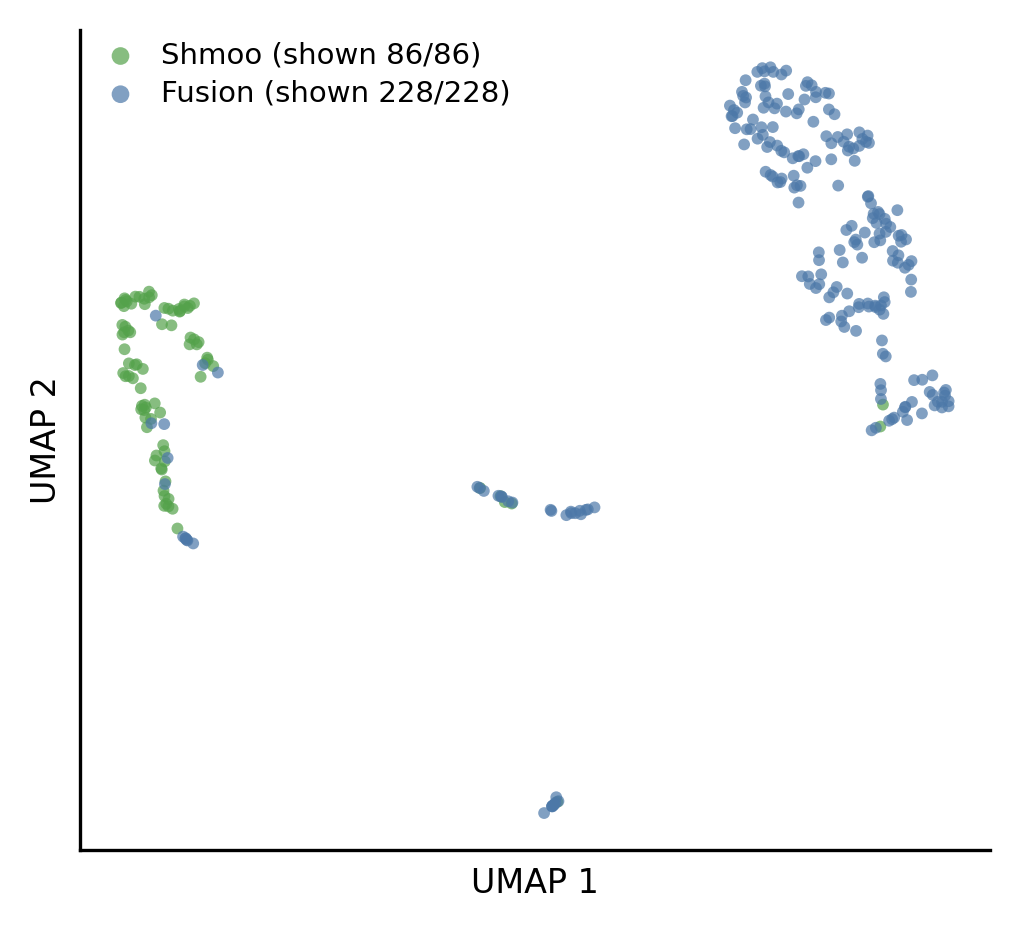

In [57]:
table = add_projection_and_clusters(table, embeddings, method="umap")
umap_coordinates = table[["umap_1", "umap_2"]].to_numpy()

plot_umap(
    coordinates=umap_coordinates,
    labels=table["label_id"].to_numpy(),
    label_names=PHENOTYPE_NAMES,
    label_colors=PHENOTYPE_COLORS,
    cutoff_number=1000,
    output_path=f"{OUTPUT_FOLDER}/umap_by_phenotype.png",
)

(<Figure size 1050x960 with 1 Axes>, <Axes: xlabel='UMAP 1', ylabel='UMAP 2'>)

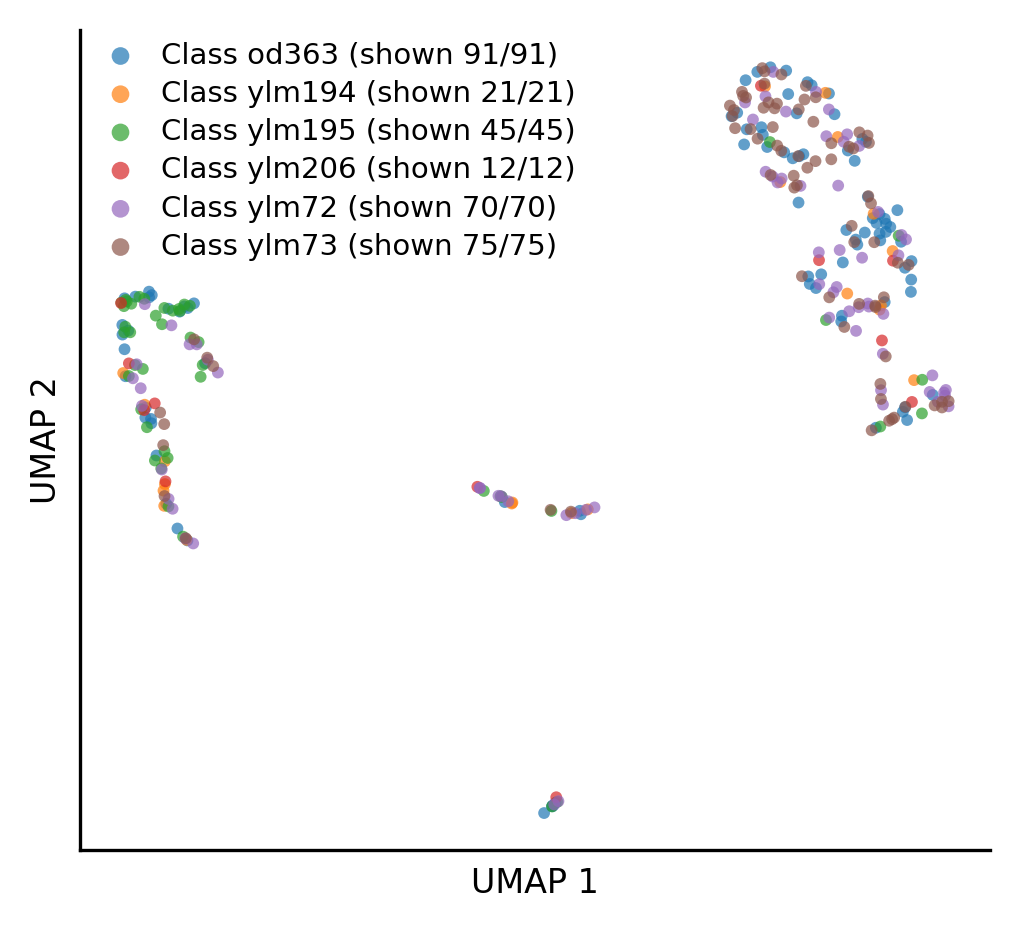

In [59]:
plot_umap(
    coordinates=umap_coordinates,
    labels=table["strain_type"],
    cutoff_number=1000,
    output_path=f"{OUTPUT_FOLDER}/umap_by_phenotype.png",
)

### 2.2 - How many sub-classes are there?

Sweep KMeans cluster counts and look at the elbow (inertia) and the
silhouette score (higher = better separated) to pick a reasonable `k`.
Clustering runs on the same L2-normalized embeddings used for UMAP, not
on the 2D projection, so it is not biased by UMAP's local distortions.

k=2: inertia=19.44, silhouette=0.878
k=3: inertia=12.75, silhouette=0.883
k=4: inertia=8.70, silhouette=0.876
k=5: inertia=6.09, silhouette=0.870
k=6: inertia=4.45, silhouette=0.867
k=7: inertia=3.62, silhouette=0.854
k=8: inertia=3.13, silhouette=0.856
k=9: inertia=2.83, silhouette=0.773
k=10: inertia=2.41, silhouette=0.839
k=11: inertia=2.11, silhouette=0.754
k=12: inertia=1.91, silhouette=0.758
k=13: inertia=1.72, silhouette=0.766
k=14: inertia=1.59, silhouette=0.747


,k,inertia,silhouette
0,2,19.437851,0.878174
1,3,12.754442,0.882901
2,4,8.702927,0.876450
3,5,6.089209,0.870055
4,6,4.445941,0.867107
5,7,3.621178,0.854424
6,8,3.129666,0.856303
7,9,2.828467,0.772822
8,10,2.413865,0.838525
9,11,2.111333,0.754252


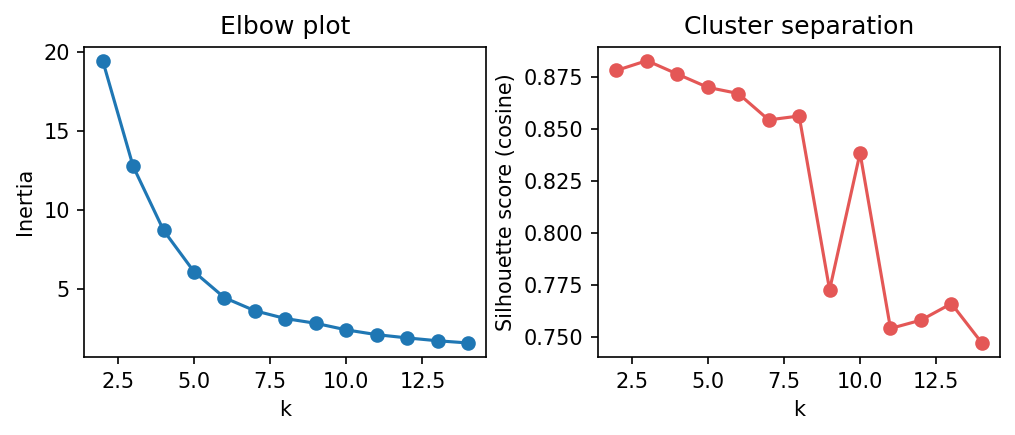

In [60]:
k_sweep = evaluate_kmeans_k(embeddings, k_values=range(2, 15))
plot_kmeans_k_sweep(k_sweep, output_path=f"{OUTPUT_FOLDER}/kmeans_k_sweep.png")
k_sweep

Running UMAP: samples=314, n_neighbors=15, min_dist=0.1, metric=cosine


/home/liwa/miniconda3/envs/oneformer/lib/python3.8/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


(<Figure size 1050x960 with 1 Axes>, <Axes: xlabel='UMAP 1', ylabel='UMAP 2'>)

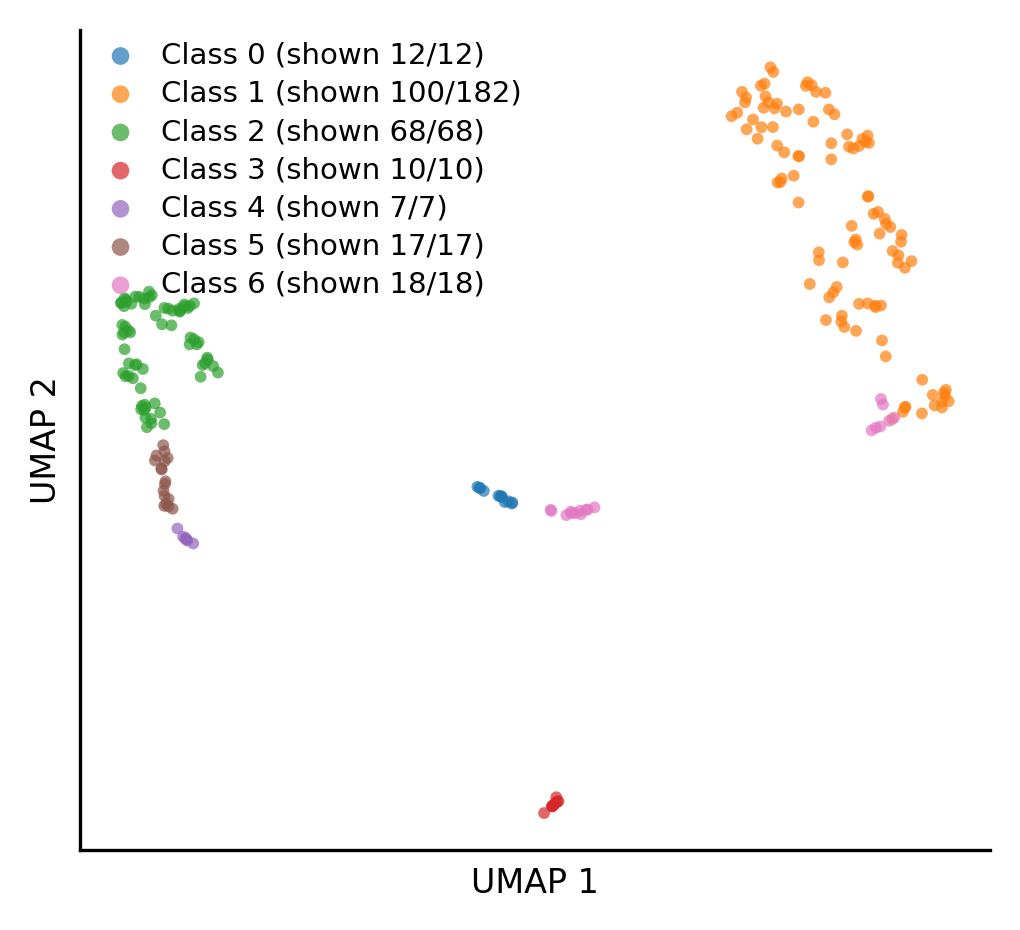

In [61]:
# Pick k from the sweep above, then assign sub-class clusters.
N_CLUSTERS = 7

table = add_projection_and_clusters(
    table, embeddings, method="umap", n_clusters=N_CLUSTERS,
)

plot_umap(
    coordinates=umap_coordinates,
    labels=table["cluster_id"].to_numpy(),
    cutoff_number=100,
    output_path=f"{OUTPUT_FOLDER}/umap_by_cluster.png",
)

Cross-tabulate clusters against the existing phenotype calls: a cluster
that splits cleanly across phenotypes is probably a real sub-class; one
that matches an existing phenotype 1:1 probably is not.

In [62]:
pd.crosstab(table["cluster_id"], table["phenotype_name"])

phenotype_name,Fusion,Shmoo
cluster_id,,
0,8,4
1,182,0
2,5,63
3,9,1
4,6,1
5,2,15
6,16,2


In [63]:
# Save the combined per-cell table (metadata + UMAP coords + cluster id).
# Embeddings stay in cells.npz; join on "cell_id" if you need them too.
table.to_csv(f"{OUTPUT_FOLDER}/cell_table.csv", index=False)

### 2.3 - Inspect a sub-cluster: original image crops

Pick a cluster (or a phenotype) of interest and look at the actual cells,
not just the embedding -- this is where you confirm whether a UMAP
sub-cluster corresponds to a real, visually distinct sub-class.

(<Figure size 1980x1320 with 24 Axes>,
 array([<Axes: title={'center': 'Shmoo (#1971)'}>,
        <Axes: title={'center': 'Shmoo (#1581)'}>,
        <Axes: title={'center': 'Shmoo (#1588)'}>,
        <Axes: title={'center': 'Shmoo (#1519)'}>,
        <Axes: title={'center': 'Shmoo (#1586)'}>,
        <Axes: title={'center': 'Fusion (#1772)'}>,
        <Axes: title={'center': 'Shmoo (#1585)'}>,
        <Axes: title={'center': 'Shmoo (#3415)'}>,
        <Axes: title={'center': 'Shmoo (#2872)'}>,
        <Axes: title={'center': 'Shmoo (#3419)'}>,
        <Axes: title={'center': 'Shmoo (#1583)'}>,
        <Axes: title={'center': 'Shmoo (#1671)'}>,
        <Axes: title={'center': 'Fusion (#4048)'}>,
        <Axes: title={'center': 'Fusion (#2969)'}>,
        <Axes: title={'center': 'Shmoo (#2411)'}>,
        <Axes: title={'center': 'Shmoo (#1670)'}>,
        <Axes: title={'center': 'Shmoo (#350)'}>,
        <Axes: title={'center': 'Shmoo (#2281)'}>,
        <Axes: title={'center': 'Shmoo (#

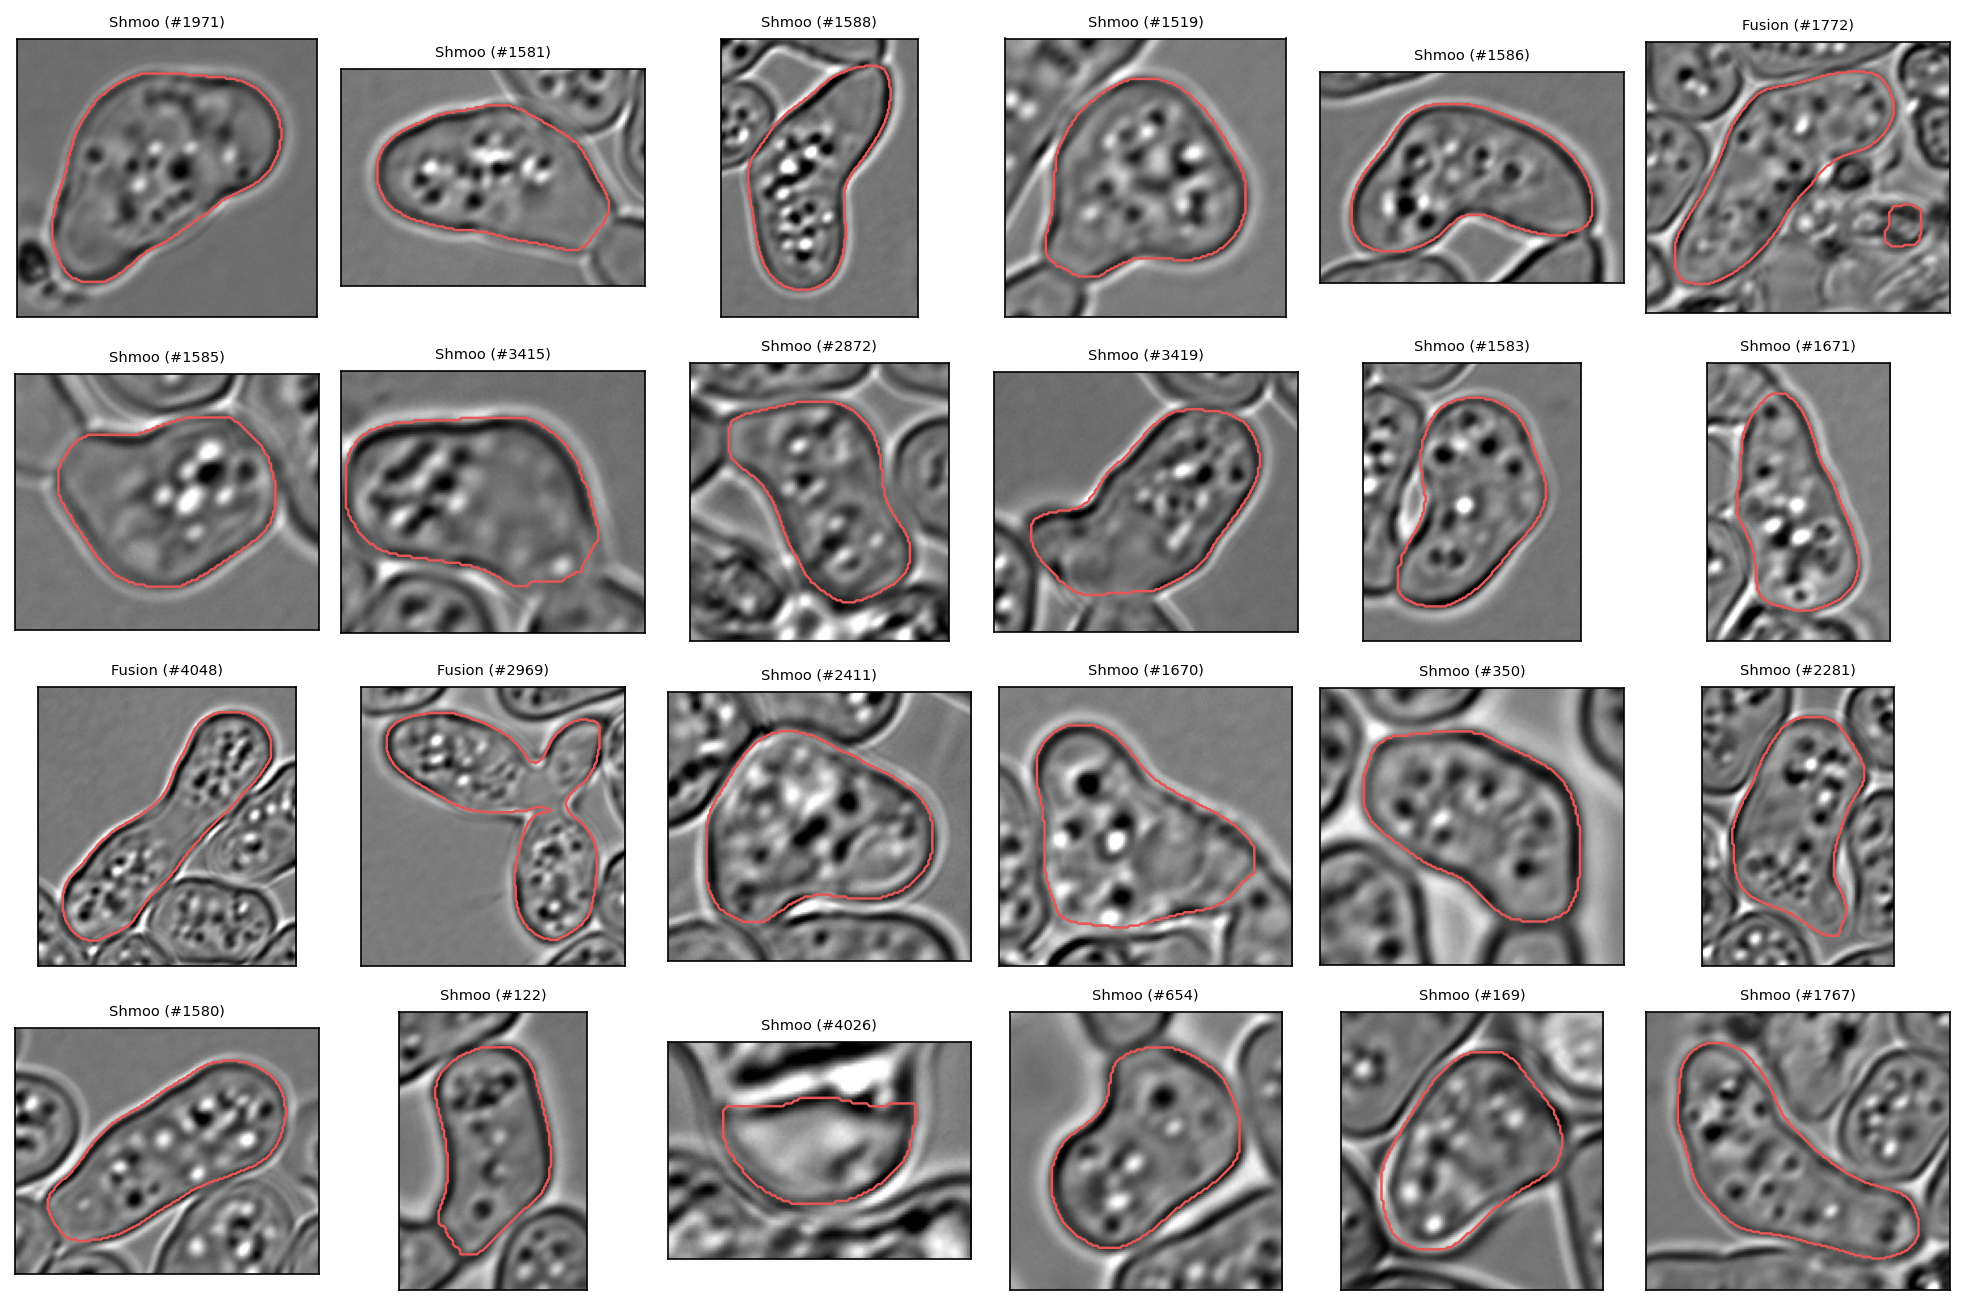

In [71]:
CLUSTER_OF_INTEREST = 2

selected_cell_ids = (
    table.loc[table["cluster_id"] == CLUSTER_OF_INTEREST, "cell_id"]
    .sample(n=min(24, (table["cluster_id"] == CLUSTER_OF_INTEREST).sum()), random_state=0)
)

plot_cell_gallery(
    table=table,
    cell_ids=selected_cell_ids,
    output_folder=OUTPUT_FOLDER,
    image_folder=IMAGE_FOLDER,
    figure_path=f"{OUTPUT_FOLDER}/cluster_{CLUSTER_OF_INTEREST}_gallery.png",
)

### 2.4 - Linked figure: one image + where its cells sit in the distribution

Left panel: a full source image with its cell masks colored by cluster.
Right panel: the full UMAP scatter with that image's cells outlined, so
you can see at a glance which part(s) of the distribution it populates.

/data/martin/liwa/PytrochDeepyeast/contrast_learning.py:2014: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


(<Figure size 1500x750 with 2 Axes>,
 (<Axes: title={'center': '20260923_shmoo_phenotype_od363_001_rgb.png'}>,
  <Axes: xlabel='Component 1', ylabel='Component 2'>))

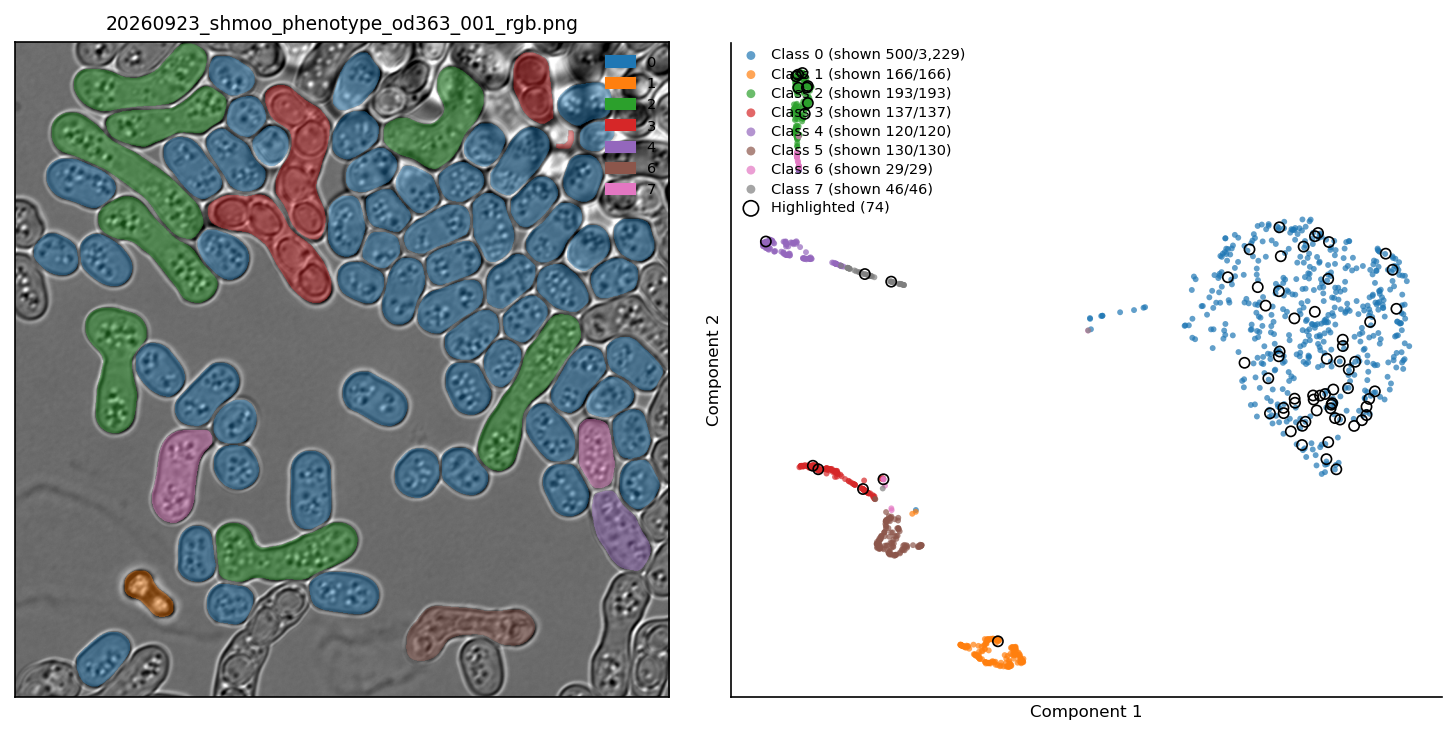

In [16]:
IMAGE_OF_INTEREST = table["image_name"].iloc[0]

plot_umap_with_image_panel(
    coordinates=umap_coordinates,
    table=table,
    image_name=IMAGE_OF_INTEREST,
    output_folder=OUTPUT_FOLDER,
    image_folder=IMAGE_FOLDER,
    color_by="cluster_id",
    figure_path=f"{OUTPUT_FOLDER}/{IMAGE_OF_INTEREST}_umap_panel.png",
)

### Resuming later / on another machine

Everything in Part 2 only needs:

- `OUTPUT_FOLDER/cells.npz` and `OUTPUT_FOLDER/masks/`
- the original images (or just re-point `IMAGE_FOLDER`)
- `OUTPUT_FOLDER/cell_table.csv` (optional convenience export from 2.2)

Re-run from the `import` cell at the top of Part 2 -- `load_cell_table()`
rebuilds everything `add_projection_and_clusters()` and the plotting
helpers need, with no model or GPU involved.